# PBrownProject2
<div style="background-color:#F3EAFB;padding:18px;border-radius:8px;color:#352147;"><strong>Tidying and Analyzing Three Discussion Datasets</strong><br>Light lavender edition</div>
**Precious Brown | IS 362 Data Acquisition and Management | Professor Larry Cohen**

This project prepares three wide datasets from Discussion 5/6 for analysis. Each section preserves the original CSV, explains the unit of observation, reshapes the data, checks that values were preserved, and answers an analysis question. The purple charts use the transformed data.

### Dataset credits and scope
* **Precious Brown:** grocery-store meat sales example from the October 4, 2026 discussion. These are constructed example values, not audited store records.
* **Joseph Damiano:** fictional public-library usage dataset, Discussion 5/6: Untidy Data, October 4, 2026. All 24 numeric values are transcribed from the supplied post.
* **Shehou Fisiru:** six basketball teams and three seasons, Discussion 5/6: Untidy Data, October 10, 2026. All 18 win/loss records are transcribed as supplied. This project does not independently verify them as official NBA results.

Joseph and Shehou receive credit for the datasets they posted, not for the transformations or interpretations developed here. The instructor's sample dataset is not used.

### Code assistance and contributions
ChatGPT assisted with drafting the original meat example, transcribing the supplied discussion tables, and drafting the Python code, validation checks, explanations, charts, and report. Precious Brown selected the meat-sales topic, selected the two classmates' posts, supplied their contents, and requested the purple presentation and explicit dataset credits. The classmates supplied their respective discussion datasets. This attribution does not claim that Precious independently wrote the generated code. Any later student-written changes should be identified by cell or section before submission.

I also created the GitHub repository, uploaded the project materials, and organized the source datasets, figures, and analysis outputs into their designated folders. This established the repository structure expected by the notebook’s relative file paths. These contributions involved project organization and submission preparation; I did not modify the supplied analysis code.

### Running the notebook
Extract the project folder and open this notebook from that folder. Install the packages in requirements.txt and run all cells in order. The three original CSV files must remain inside data. Output CSVs and figures are regenerated in output and figures. No internet connection is needed for the analysis.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path('data')
OUT = Path('output')
FIGURES = Path('figures')
OUT.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)
PURPLES = ['#A78BCA', '#BDA3DF', '#CBB6E8', '#DDCEF1', '#9673BB', '#78529B']
plt.rcParams.update({'figure.facecolor': 'white', 'axes.facecolor': '#FBF8FF',
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'font.size': 10, 'figure.dpi': 120})
pd.set_option('display.max_columns', 12)

# Source rows must be complete and unique; never silently discard data.
def audit_wide(frame, key, expected_rows):
    assert len(frame) == expected_rows, 'Unexpected source row count'
    assert not frame.isna().any().any(), 'Missing source values need review'
    assert not frame.duplicated(key).any(), 'Duplicate source keys need review'
    print(f'{len(frame)} source rows; no missing values or duplicate keys.')

def integer_counts(series):
    numeric = pd.to_numeric(series, errors='raise')
    assert numeric.notna().all(), 'Missing counts need review'
    assert (numeric >= 0).all(), 'Negative counts need review'
    assert (numeric % 1 == 0).all(), 'Noninteger counts need review'
    return numeric.astype('int64')

## 1 Grocery store meat sales
**Dataset credit:** Precious Brown, October 4, 2026 discussion example, drafted with ChatGPT assistance.

**Question:** Which meats sell the most by weight, and how does monthly sales volume change? What cautious inventory-planning observations follow?

The wide source has one row per meat and three month columns. Month names are values of a variable, not separate measurements. The tidy unit is **one meat in one month**, with columns meat, month, and pounds_sold. No year was supplied, so no year is invented.

In [2]:
meat_raw = pd.read_csv(DATA / 'MeatSales.csv')
audit_wide(meat_raw, ['Type of Meat'], 5)
display(meat_raw)

,Type of Meat,January Pounds Sold,February Pounds Sold,March Pounds Sold
0,Chicken,850,920,980
1,Beef,640,610,720
2,Pork,420,390,450
3,Turkey,280,240,260
4,Lamb,150,170,210


5 source rows; no missing values or duplicate keys.


### Meat cleanup and transformation
I standardize the identifier name and trim its labels in a working copy, then use melt to gather the month columns. I remove the repeated unit phrase from each month label, store the unit explicitly in pounds_sold, enforce numeric nonnegative integer counts, and order the months chronologically. The original files are not overwritten. No missing values or duplicates were found, so no imputation or row deletion is justified.

In [3]:
month_columns = ['January Pounds Sold', 'February Pounds Sold', 'March Pounds Sold']
month_order = ['January', 'February', 'March']
meat = meat_raw.rename(columns={'Type of Meat': 'meat'}).copy()
meat['meat'] = meat['meat'].str.strip()
meat = meat.melt(id_vars='meat', value_vars=month_columns,
                 var_name='month', value_name='pounds_sold')
meat['month'] = meat['month'].str.replace(' Pounds Sold', '', regex=False)
assert meat['month'].isin(month_order).all()
meat['month'] = pd.Categorical(meat['month'], categories=month_order, ordered=True)
meat['pounds_sold'] = integer_counts(meat['pounds_sold'])
meat = meat.sort_values(['meat', 'month']).reset_index(drop=True)
assert len(meat) == 15 and not meat.duplicated(['meat', 'month']).any()
assert meat['pounds_sold'].sum() == meat_raw[month_columns].to_numpy().sum()
# Round-trip check confirms every original number, not only the total.
meat_back = meat.pivot(index='meat', columns='month', values='pounds_sold')
for month, source_column in zip(month_order, month_columns):
    expected = meat_raw.set_index('Type of Meat')[source_column].sort_index()
    actual = meat_back[month].sort_index()
    pd.testing.assert_series_equal(actual, expected, check_names=False)
display(meat)
print('Validated all 15 meat-month values against the source.')

,meat,month,pounds_sold
0,Beef,January,640
1,Beef,February,610
2,Beef,March,720
3,Chicken,January,850
4,Chicken,February,920
5,Chicken,March,980
6,Lamb,January,150
7,Lamb,February,170
8,Lamb,March,210
9,Pork,January,420


Validated all 15 meat-month values against the source.


In [4]:
meat_totals = meat.groupby('meat')['pounds_sold'].sum().sort_values(ascending=False)
monthly_totals = meat.groupby('month', observed=True)['pounds_sold'].sum()
meat_summary = meat_totals.to_frame('total_pounds')
meat_summary['share_percent'] = meat_totals / meat_totals.sum() * 100
meat_summary['jan_to_mar_pounds'] = meat_back['March'] - meat_back['January']
meat_summary['jan_to_mar_percent'] = (
    (meat_back['March'] / meat_back['January'] - 1) * 100
)
month_summary = monthly_totals.to_frame('total_pounds')
month_summary['change_pounds'] = monthly_totals.diff()
month_summary['change_percent'] = monthly_totals.pct_change(fill_method=None) * 100
display(meat_summary.round(2))
display(month_summary.round(2))

,total_pounds,share_percent,jan_to_mar_pounds,jan_to_mar_percent
meat,,,,
Chicken,2750,37.72,130,15.29
Beef,1970,27.02,80,12.50
Pork,1260,17.28,30,7.14
Turkey,780,10.70,-20,-7.14
Lamb,530,7.27,60,40.00


,total_pounds,change_pounds,change_percent
month,,,
January,2340,NaN,NaN
February,2330,-10.0,-0.43
March,2620,290.0,12.45


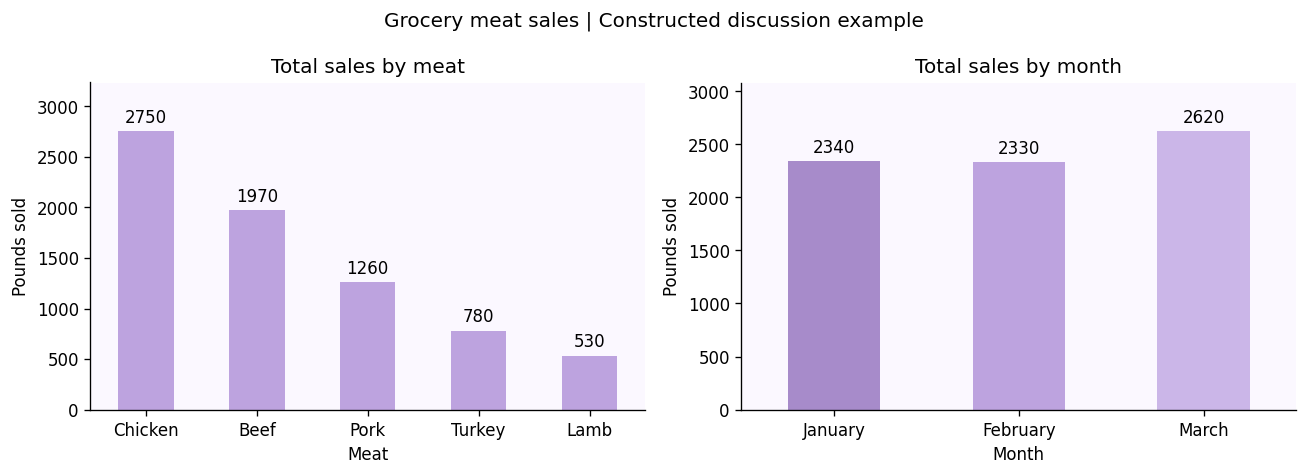

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
meat_totals.plot.bar(ax=axes[0], color=PURPLES[1], rot=0)
axes[0].set(title='Total sales by meat', xlabel='Meat', ylabel='Pounds sold')
axes[0].bar_label(axes[0].containers[0], padding=3)
monthly_totals.plot.bar(ax=axes[1], color=PURPLES[:3], rot=0)
axes[1].set(title='Total sales by month', xlabel='Month', ylabel='Pounds sold')
axes[1].bar_label(axes[1].containers[0], padding=3)
for ax in axes:
    ax.set_ylim(0, ax.get_ylim()[1] * 1.12)
fig.suptitle('Grocery meat sales | Constructed discussion example')
fig.tight_layout()
fig.savefig(FIGURES / 'MeatSales.png', bbox_inches='tight')
plt.show()

### Meat findings and limitations
Chicken has the highest total, **2,750 pounds**, followed by beef at **1,970 pounds**. Across all meats, the total is **7,290 pounds**. Monthly totals are **2,340** in January, **2,330** in February, and **2,620** in March. March is **12.45%** above February and **11.97%** above January.

Lamb has the largest January-to-March percentage increase (**40%**, from 150 to 210 pounds), while chicken has the largest absolute increase (**130 pounds**). Turkey declines by 20 pounds (**7.14%**).

These sample values suggest reviewing chicken and beef replenishment first and investigating the March increase. They do not establish profit, future demand, seasonality, or actual waste. Prices, stockouts, purchases, spoilage, and more months of data would be needed to make those claims. The first month has no prior comparison; its change stays missing rather than being set to zero.

## 2 Public library usage
**Dataset credit:** Joseph Damiano. *Discussion 5/6: Untidy Data*, October 4, 2026. Joseph explicitly describes the values as fictional monthly sample data. The month and year of the counts are not specified.

**Questions from Joseph's post:** How does resource usage differ across age groups and branches? Which groups use computers more relative to books, and which branches record the most youth or senior usage?

The source has one row per branch and service, with age groups spread across columns. I first melt the age columns to make one branch-service-age observation per row. Then I pivot service type into separate books_borrowed and computer_sessions measures. This final table has **one branch and age group per row**. Keeping the units separate avoids equating books with computer sessions.

In [6]:
library_raw = pd.read_csv(DATA / 'LibraryUsage.csv')
audit_wide(library_raw, ['Branch', 'Service Type'], 6)
display(library_raw)

,Branch,Service Type,Kids (0-12),Teens (13-18),Adults (19-64),Seniors (65+)
0,Downtown,Books Borrowed,520,180,940,610
1,Downtown,Computer Sessions,110,320,580,210
2,Northside,Books Borrowed,340,115,620,450
3,Northside,Computer Sessions,85,210,390,140
4,West End,Books Borrowed,210,90,430,380
5,West End,Computer Sessions,45,160,290,95


6 source rows; no missing values or duplicate keys.


In [7]:
age_columns = ['Kids (0-12)', 'Teens (13-18)', 'Adults (19-64)', 'Seniors (65+)']
library_long = library_raw.rename(columns={'Branch': 'branch',
                                           'Service Type': 'service_type'}).copy()
for column in ['branch', 'service_type']:
    library_long[column] = library_long[column].str.strip()
library_long = library_long.melt(
    id_vars=['branch', 'service_type'], value_vars=age_columns,
    var_name='age_group', value_name='usage_count'
)
library_long['usage_count'] = integer_counts(library_long['usage_count'])
assert len(library_long) == 24
assert not library_long.duplicated(['branch', 'service_type', 'age_group']).any()
assert set(library_long['service_type']) == {'Books Borrowed', 'Computer Sessions'}
library = library_long.pivot(
    index=['branch', 'age_group'], columns='service_type', values='usage_count'
).rename(columns={'Books Borrowed': 'books_borrowed',
                   'Computer Sessions': 'computer_sessions'}).reset_index()
library.columns.name = None
library['age_group'] = pd.Categorical(
    library['age_group'], categories=age_columns, ordered=True
)
library = library.sort_values(['branch', 'age_group']).reset_index(drop=True)
assert len(library) == 12 and not library.isna().any().any()
assert not library.duplicated(['branch', 'age_group']).any()
# Check every source cell after melting, rather than relying on a grand total.
library_back = library_long.pivot(
    index=['branch', 'service_type'], columns='age_group', values='usage_count'
)
library_expected = library_raw.set_index(['Branch', 'Service Type'])[age_columns]
pd.testing.assert_frame_equal(
    library_back[age_columns].sort_index(), library_expected.sort_index(),
    check_names=False
)
display(library)
print('Validated all 24 usage values; final table has 12 branch-age rows.')

,branch,age_group,books_borrowed,computer_sessions
0,Downtown,Kids (0-12),520,110
1,Downtown,Teens (13-18),180,320
2,Downtown,Adults (19-64),940,580
3,Downtown,Seniors (65+),610,210
4,Northside,Kids (0-12),340,85
5,Northside,Teens (13-18),115,210
6,Northside,Adults (19-64),620,390
7,Northside,Seniors (65+),450,140
8,West End,Kids (0-12),210,45
9,West End,Teens (13-18),90,160


Validated all 24 usage values; final table has 12 branch-age rows.


### Library comparisons
I aggregate each service separately. The computer-to-book ratio describes recorded sessions per book borrowed; it is not the percentage of patrons who prefer computers. Youth is defined here as kids and teens combined. No population denominators or unique-user identifiers are available.

In [8]:
measures = ['books_borrowed', 'computer_sessions']
age_summary = library.groupby('age_group', observed=True)[measures].sum()
assert (age_summary['books_borrowed'] > 0).all()
age_summary['sessions_per_book'] = (
    age_summary['computer_sessions'] / age_summary['books_borrowed']
)
branch_summary = library.groupby('branch')[measures].sum()
youth_summary = library.loc[library['age_group'].isin(age_columns[:2])].groupby('branch')[measures].sum()
senior_summary = library.loc[library['age_group'] == 'Seniors (65+)'].groupby('branch')[measures].sum()
print('Usage by age group')
display(age_summary.round(3))
print('Usage by branch')
display(branch_summary)
print('Youth usage by branch')
display(youth_summary)
print('Senior usage by branch')
display(senior_summary)

,books_borrowed,computer_sessions,sessions_per_book
age_group,,,
Kids (0-12),1070,240,0.224
Teens (13-18),385,690,1.792
Adults (19-64),1990,1260,0.633
Seniors (65+),1440,445,0.309


,books_borrowed,computer_sessions
branch,,
Downtown,2250,1220
Northside,1525,825
West End,1110,590


,books_borrowed,computer_sessions
branch,,
Downtown,700,430
Northside,455,295
West End,300,205


,books_borrowed,computer_sessions
branch,,
Downtown,610,210
Northside,450,140
West End,380,95


Usage by age group
Usage by branch
Youth usage by branch
Senior usage by branch


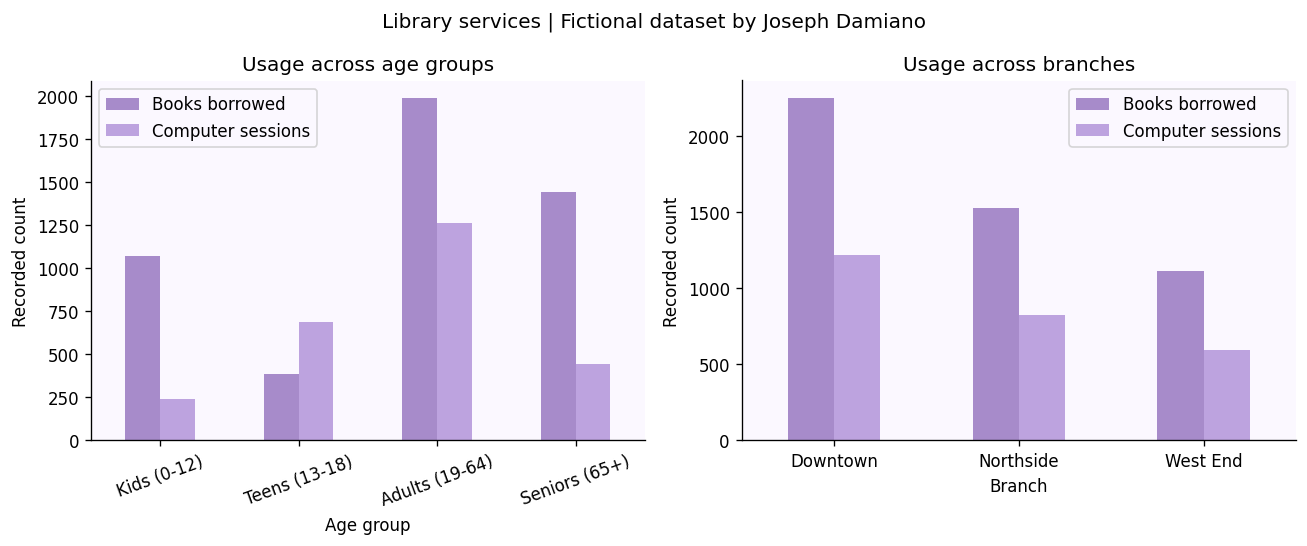

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
age_summary[measures].rename(columns={'books_borrowed': 'Books borrowed',
                                      'computer_sessions': 'Computer sessions'}).plot.bar(
    ax=axes[0], color=PURPLES[:2], rot=20
)
axes[0].set(title='Usage across age groups', xlabel='Age group', ylabel='Recorded count')
branch_summary.rename(columns={'books_borrowed': 'Books borrowed',
                                'computer_sessions': 'Computer sessions'}).plot.bar(
    ax=axes[1], color=PURPLES[:2], rot=0
)
axes[1].set(title='Usage across branches', xlabel='Branch', ylabel='Recorded count')
fig.suptitle('Library services | Fictional dataset by Joseph Damiano')
fig.tight_layout()
fig.savefig(FIGURES / 'LibraryUsage.png', bbox_inches='tight')
plt.show()

### Library findings and limitations
Adults have the largest absolute totals for both services: **1,990 books** and **1,260 computer sessions**. Teens have the highest computer-to-book ratio: **690 / 385 = 1.792 sessions per book**. That ratio indicates the strongest relative computer usage in this sample, not a measured preference or dependency.

Downtown has the largest overall volume: **2,250 books** and **1,220 computer sessions**. It also leads youth usage (**700 books; 430 sessions**) and senior usage (**610 books; 210 sessions**). Northside records **455 youth books and 295 youth sessions**, and West End records **300 youth books and 205 youth sessions**. Senior counts are **450 books and 140 sessions** at Northside and **380 books and 95 sessions** at West End.

The fictional example suggests considering teen computer access and reviewing Downtown's capacity. It cannot establish which branch serves the largest youth or senior population because one person may generate many transactions. Branch size, operating hours, unique patrons, wait times, costs, and service capacity are needed before allocating funding.

## 3 Basketball win and loss records
**Dataset credit:** Shehou Fisiru. *Discussion 5/6: Untidy Data*, October 10, 2026. Values are reproduced from the supplied discussion post, without substitution from external sports sources.

Shehou explains why the table is untidy but does not state an analysis question. **Questions selected for this project:** Which team has the highest win percentage in each season, which improves most from 2023-24 to 2025-26, and how do the selected East and West teams compare?

The table has two structural issues: seasons appear in column headers, and each cell combines wins and losses. I melt the season columns, validate the record syntax, split the values, and convert them to integers. The final unit is **one team in one season**. I retain conference as context and derive games, win percentage, and season start year.

In [10]:
basketball_raw = pd.read_csv(DATA / 'BasketballRecords.csv', dtype=str)
audit_wide(basketball_raw, ['Team'], 6)
display(basketball_raw)

,Team,Conference,2023-24,2024-25,2025-26
0,New York Knicks,East,50-32,51-31,53-29
1,Boston Celtics,East,64-18,61-21,56-26
2,Detroit Pistons,East,14-68,44-38,60-22
3,Oklahoma City Thunder,West,57-25,68-14,64-18
4,San Antonio Spurs,West,22-60,34-48,62-20
5,Denver Nuggets,West,57-25,50-32,54-28


6 source rows; no missing values or duplicate keys.


In [11]:
seasons = ['2023-24', '2024-25', '2025-26']
basketball = basketball_raw.rename(columns={'Team': 'team', 'Conference': 'conference'}).copy()
for column in ['team', 'conference']:
    basketball[column] = basketball[column].str.strip()
basketball = basketball.melt(id_vars=['team', 'conference'], value_vars=seasons,
                             var_name='season', value_name='record')
basketball['record'] = basketball['record'].str.strip()
assert basketball['record'].str.fullmatch(r'\d+-\d+').all(), 'Malformed win-loss record'
parts = basketball['record'].str.split('-', expand=True)
basketball['wins'] = integer_counts(parts[0])
basketball['losses'] = integer_counts(parts[1])
basketball['games'] = basketball['wins'] + basketball['losses']
assert basketball['games'].eq(82).all(), 'Source record is not an 82-game season'
assert basketball['conference'].isin(['East', 'West']).all()
basketball['win_percent'] = basketball['wins'] / basketball['games'] * 100
basketball['season_start'] = basketball['season'].str[:4].astype('int64')
# Reconstruct every original record before dropping the combined field.
basketball['reconstructed'] = basketball['wins'].astype(str) + '-' + basketball['losses'].astype(str)
assert basketball['reconstructed'].equals(basketball['record'])
basketball_back = basketball.pivot(index='team', columns='season', values='reconstructed')
pd.testing.assert_frame_equal(
    basketball_back[seasons].sort_index(),
    basketball_raw.set_index('Team')[seasons].sort_index(), check_names=False
)
basketball = basketball.drop(columns=['record', 'reconstructed'])
basketball = basketball.sort_values(['team', 'season_start']).reset_index(drop=True)
assert len(basketball) == 18 and not basketball.duplicated(['team', 'season']).any()
assert not basketball.isna().any().any()
display(basketball.round(2))
print('Validated all 18 records; each supplied record totals 82 games.')

,team,conference,season,wins,losses,games,win_percent,season_start
0,Boston Celtics,East,2023-24,64,18,82,78.05,2023
1,Boston Celtics,East,2024-25,61,21,82,74.39,2024
2,Boston Celtics,East,2025-26,56,26,82,68.29,2025
3,Denver Nuggets,West,2023-24,57,25,82,69.51,2023
4,Denver Nuggets,West,2024-25,50,32,82,60.98,2024
5,Denver Nuggets,West,2025-26,54,28,82,65.85,2025
6,Detroit Pistons,East,2023-24,14,68,82,17.07,2023
7,Detroit Pistons,East,2024-25,44,38,82,53.66,2024
8,Detroit Pistons,East,2025-26,60,22,82,73.17,2025
9,New York Knicks,East,2023-24,50,32,82,60.98,2023


Validated all 18 records; each supplied record totals 82 games.


In [12]:
# Include all tied leaders, if any, instead of silently choosing just one.
season_best = basketball.groupby('season')['win_percent'].transform('max')
leaders = basketball.loc[basketball['win_percent'].eq(season_best),
                          ['season', 'team', 'wins', 'losses', 'win_percent']]
leaders = leaders.sort_values('season').reset_index(drop=True)
wins_by_season = basketball.pivot(index='team', columns='season', values='wins')[seasons]
improvement = wins_by_season.copy()
improvement['change_wins'] = improvement[seasons[-1]] - improvement[seasons[0]]
improvement['change_percentage_points'] = improvement['change_wins'] / 82 * 100
improvement = improvement.sort_values('change_wins', ascending=False)
conference_summary = basketball.groupby(['season', 'conference']).agg(
    teams=('team', 'nunique'), wins=('wins', 'sum'), games=('games', 'sum')
)
conference_summary['win_percent'] = conference_summary['wins'] / conference_summary['games'] * 100
display(leaders.round(2))
display(improvement.round(2))
display(conference_summary.round(2))

,season,team,wins,losses,win_percent
0,2023-24,Boston Celtics,64,18,78.05
1,2024-25,Oklahoma City Thunder,68,14,82.93
2,2025-26,Oklahoma City Thunder,64,18,78.05


season,2023-24,2024-25,2025-26,change_wins,change_percentage_points
team,,,,,
Detroit Pistons,14,44,60,46,56.10
San Antonio Spurs,22,34,62,40,48.78
Oklahoma City Thunder,57,68,64,7,8.54
New York Knicks,50,51,53,3,3.66
Denver Nuggets,57,50,54,-3,-3.66
Boston Celtics,64,61,56,-8,-9.76


teams  wins  games  win_percent
season  conference                                 
2023-24 East            3   128    246        52.03
        West            3   136    246        55.28
2024-25 East            3   156    246        63.41
        West            3   152    246        61.79
2025-26 East            3   169    246        68.70
        West            3   180    246        73.17

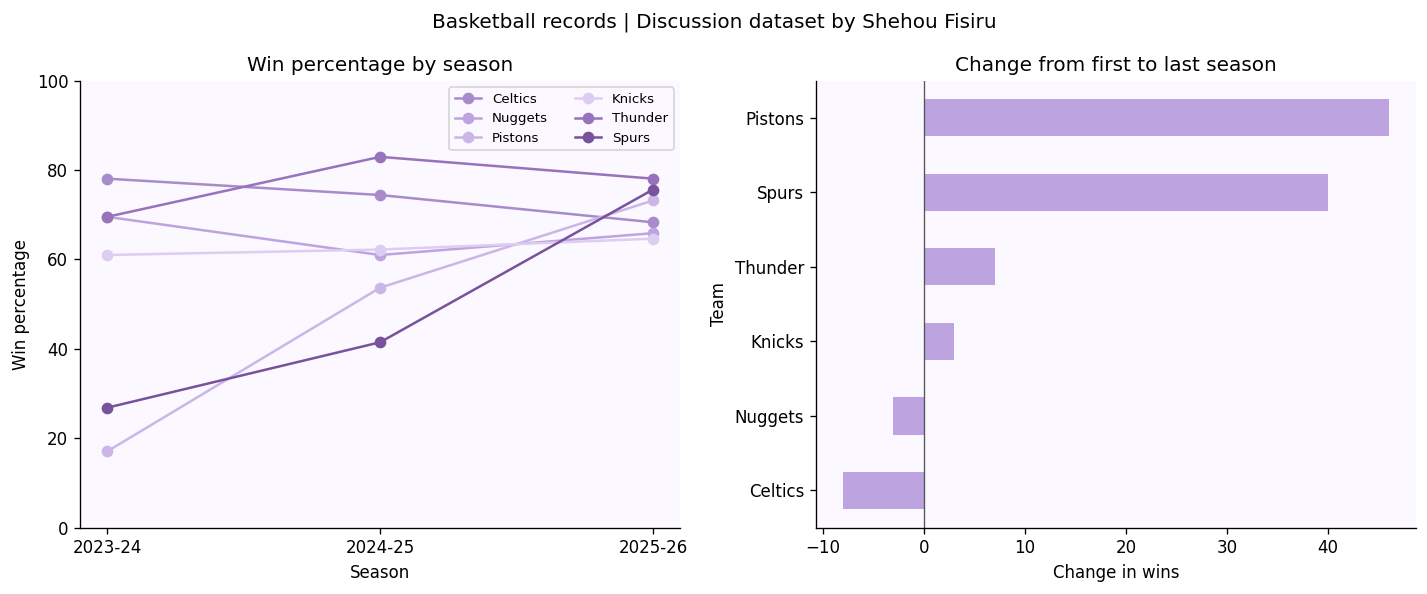

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
short_names = {'New York Knicks': 'Knicks', 'Boston Celtics': 'Celtics',
               'Detroit Pistons': 'Pistons', 'Oklahoma City Thunder': 'Thunder',
               'San Antonio Spurs': 'Spurs', 'Denver Nuggets': 'Nuggets'}
for color, (team, row) in zip(PURPLES, wins_by_season.iterrows()):
    axes[0].plot(seasons, row / 82 * 100, marker='o', color=color,
                 label=short_names[team])
axes[0].set(title='Win percentage by season', xlabel='Season', ylabel='Win percentage', ylim=(0, 100))
axes[0].legend(ncol=2, fontsize=8)
improvement['change_wins'].rename(index=short_names).sort_values().plot.barh(
    ax=axes[1], color=PURPLES[1]
)
axes[1].axvline(0, color='#555555', linewidth=0.8)
axes[1].set(title='Change from first to last season', xlabel='Change in wins', ylabel='Team')
fig.suptitle('Basketball records | Discussion dataset by Shehou Fisiru')
fig.tight_layout()
fig.savefig(FIGURES / 'BasketballRecords.png', bbox_inches='tight')
plt.show()

### Basketball findings and limitations
Within the supplied six-team sample, Boston leads 2023-24 with **64 wins (78.05%)**. Oklahoma City leads 2024-25 with **68 wins (82.93%)** and 2025-26 with **64 wins (78.05%)**.

Detroit has the largest first-to-last improvement: **46 additional wins**, from 14 to 60, equivalent to **56.10 percentage points**. San Antonio improves by **40 wins**, Oklahoma City by **7**, and New York by **3**. Boston declines by **8 wins**, and Denver declines by **3**. Percentage-point change is distinct from relative percentage growth.

The selected East teams have combined win percentages of **52.03%, 63.41%, and 68.70%** across the three seasons. The selected West teams have **55.28%, 61.79%, and 73.17%**. These are comparisons of three selected teams per conference, not full-conference standings. All records total 82 games, which checks internal consistency but does not verify real-world accuracy. The analysis cannot establish why performance changed.

## 4 Export and conclusion
The transformed datasets preserve the supplied values while giving each observation a consistent structure. Meat sales require a month variable; library usage requires age groups in rows and separate service measures; basketball records require both reshaping and splitting composite values. Validation checks cover missingness, keys, row counts, numeric values, and round-trip reconstruction.

The results identify chicken as the largest meat category, adults as the largest absolute library-service group and teens as the highest relative computer-use group, and Detroit as the largest basketball improver within the supplied records. These conclusions are limited to the provided examples.

The CSV outputs below are derivatives; data contains the unchanged wide inputs. Rounded values appear only in displays, while calculations and exports retain their precision.

In [14]:
exports = {
    'MeatSalesTidy.csv': meat,
    'LibraryUsageLong.csv': library_long,
    'LibraryUsageTidy.csv': library,
    'BasketballRecordsTidy.csv': basketball,
    'MeatSummary.csv': meat_summary.reset_index(),
    'MonthlyMeatSummary.csv': month_summary.reset_index(),
    'LibraryAgeSummary.csv': age_summary.reset_index(),
    'LibraryBranchSummary.csv': branch_summary.reset_index(),
    'LibraryYouthSummary.csv': youth_summary.reset_index(),
    'LibrarySeniorSummary.csv': senior_summary.reset_index(),
    'BasketballLeaders.csv': leaders,
    'BasketballImprovement.csv': improvement.reset_index(),
    'BasketballConferenceSummary.csv': conference_summary.reset_index()
}
for filename, frame in exports.items():
    frame.to_csv(OUT / filename, index=False)
print(f'Exported {len(exports)} tables. All validation checks passed.')

Exported 13 tables. All validation checks passed.


## References and acknowledgments
1. Brown, Precious. (2026, October 4). Grocery-store meat sales example. Discussion 5/6: Untidy Data, IS 362, CUNY School of Professional Studies. Constructed example drafted with ChatGPT assistance.
2. Damiano, Joseph. (2026, October 4). Discussion 5/6: Untidy Data. IS 362 course discussion, CUNY School of Professional Studies. Fictional library-usage table and proposed resource-usage questions, supplied as a screenshot.
3. Fisiru, Shehou. (2026, October 10). Discussion 5/6: Untidy Data. IS 362 course discussion, CUNY School of Professional Studies. Basketball table and explanation of its untidy structure, supplied as a screenshot and text.
4. Cohen, Larry. IS 362 Project 2 assignment instructions and course syllabus. CUNY School of Professional Studies. Materials supplied by the student.
5. OpenAI, ChatGPT. (2026, October 11). Assistance with transcription, Python transformations, validation, analysis, visualization, and document preparation. See the contribution statement at the beginning of this notebook.

The course discussion is not publicly linked here. Classmate names, dates, and the discussion title identify the original contributions without inventing URLs.